# Experiment 048: GPT-2 LoRA scale family

I compare here finished GPT-2 124M, 355M, 774M, XL 1.5B pipelines. It keeps generated accuracy, extraction coverage and the format-free probe separate. And shows the Qwen2.5 results as a separate family model context.

In [22]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / 'config.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / 'config.py').exists(), 'run this notebook from the code repository'
sys.path.insert(0, str(ROOT))

from analysis.stats import align_pred_rows, holm, mcnemar_exact, paired_delta_ci
from scripts.s12_eval import atomic_write_json, sha256
from scripts.s46_gpt2_xl import arm_state as arm_state_046
from scripts.s48_gpt2_lora_scales import arm_state as arm_state_048

RESULTS = ROOT / 'results'
FIG = ROOT / 'analysis' / 'figures' / '048_1'
FIG.mkdir(parents=True, exist_ok=True)
SEEDS = (0, 1, 2)
TIERS = ('easy', 'medium', 'hard')
COLORS = {'Base': '#9C9C9C', 'SFT': '#4C78A8', 'GRPO': '#F58518'}

GPT_SPECS = {
    '124M': {'params': .124, 'package': '048',
             'tag': '048_COLAB_FULL_GPT2_M124_sft_grpo_seed{seed}',
             'base': '042_COLAB_FULL_M124_base', 'base_package': '042'},
    '355M': {'params': .355, 'package': '048',
             'tag': '048_COLAB_FULL_GPT2_M355_sft_grpo_seed{seed}',
             'base': '048_COLAB_FULL_GPT2_M355_base', 'base_package': '048'},
    '774M': {'params': .774, 'package': '048',
             'tag': '048_COLAB_FULL_GPT2_M774_sft_grpo_seed{seed}',
             'base': '048_COLAB_FULL_GPT2_M774_base', 'base_package': '048'},
    'XL 1.5B': {'params': 1.5, 'package': '046',
                'tag': '046_COLAB_FULL_GPT2_B15_sft_grpo_seed{seed}',
                'base': '046_COLAB_FULL_GPT2_B15_base', 'base_package': '046'},
}
QWEN_SPECS = {
    '0.5B': {'params': .5, 'tag': '006_COLAB_FULL_B05_sft_grpo_seed{seed}'},
    '1.5B': {'params': 1.5, 'tag': '009_COLAB_FULL_B15_sft_grpo_seed{seed}'},
    '3B': {'params': 3.0, 'tag': '003_COLAB_FULL_B3_sft_grpo_seed{seed}'},
    '7B': {'params': 7.0, 'tag': '013_COLAB_FULL_B7_sft_grpo_seed{seed}'},
}

def read_json(path):
    with open(path) as handle:
        return json.load(handle)

def read_rows(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]

def accuracy(rows):
    return float(np.mean([bool(row['correct']) for row in rows]))

def verify_result_chain(result_dir, package):
    complete_path = result_dir / f'{package}_arm_complete.json'
    complete = read_json(complete_path)
    expected = {f'{package}_{branch}_{kind}.json'
                for branch in ('sft', 'grpo')
                for kind in ('training', 'eval_manifest')}
    assert complete['completed'] is True and complete['experiment'] == package
    assert set(complete['sha256']) == expected
    for name, digest in complete['sha256'].items():
        assert sha256(str(result_dir / name)) == digest
    records = {}
    for branch in ('sft', 'grpo'):
        training = read_json(result_dir / f'{package}_{branch}_training.json')
        endpoint = read_json(result_dir / f'{package}_{branch}_eval_manifest.json')
        files = {f'{branch}_preds.jsonl', f'{branch}_eval.json',
                 f'{branch}_logprob_preds.jsonl', f'{branch}_logprob.json'}
        assert training['completed'] is True and training['stage'] == branch
        assert training['experiment'] == package and training['updates'] == 500
        assert endpoint['completed'] is True and endpoint['branch'] == branch
        assert endpoint['experiment'] == package and endpoint['binding'] == training
        assert set(endpoint['sha256']) == files
        for name, digest in endpoint['sha256'].items():
            assert sha256(str(result_dir / name)) == digest
        records[branch] = training
    return complete_path, records

plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})

## Completion

In [23]:
# verify the committed records before using result values
gpt_runs = {}
source_hashes = {}
health_rows = []
for scale, spec in GPT_SPECS.items():
    base_dir = RESULTS / spec['base']
    base_manifest_path = base_dir / f"{spec['base_package']}_base_eval_manifest.json"
    base_manifest = read_json(base_manifest_path)
    assert base_manifest['completed'] is True and base_manifest['branch'] == 'base'
    for name, digest in base_manifest['sha256'].items():
        assert sha256(str(base_dir / name)) == digest
    gpt_runs[scale] = {'base': {
        'rows': read_rows(base_dir / 'base_preds.jsonl'),
        'probe_rows': read_rows(base_dir / 'base_logprob_preds.jsonl'),
        'eval': read_json(base_dir / 'base_eval.json'),
        'probe': read_json(base_dir / 'base_logprob.json'),
    }}
    source_hashes[spec['base']] = sha256(str(base_manifest_path))
    for seed in SEEDS:
        tag = spec['tag'].format(seed=seed)
        result_dir = RESULTS / tag
        complete_path, training_records = verify_result_chain(result_dir, spec['package'])
        artifact_paths = [Path(record['artifact']['path'])
                          for record in training_records.values()]
        if all(path.exists() for path in artifact_paths):
            state_fn = arm_state_046 if spec['package'] == '046' else arm_state_048
            assert state_fn(str(result_dir))['state'] == 'committed'
            verification = 'results and checkpoints'
        else:
            for record, path in zip(training_records.values(), artifact_paths):
                assert record['artifact']['kind'] == 'adapter'
                assert record['artifact']['sha256'] and str(path).startswith('/content/drive/')
            verification = 'result records'
        gpt_runs[scale][seed] = {}
        for branch in ('sft', 'grpo'):
            rows = read_rows(result_dir / f'{branch}_preds.jsonl')
            probe_rows = read_rows(result_dir / f'{branch}_logprob_preds.jsonl')
            assert len(rows) == len(probe_rows) == 1884
            assert [(row['subject'], row['tier'], row['gold']) for row in rows] == [
                (row['subject'], row['tier'], row['gold']) for row in probe_rows]
            gpt_runs[scale][seed][branch] = {
                'rows': rows, 'probe_rows': probe_rows,
                'eval': read_json(result_dir / f'{branch}_eval.json'),
                'probe': read_json(result_dir / f'{branch}_logprob.json'),
            }
        gpt_runs[scale][seed]['trainlog'] = read_json(result_dir / 'grpo_trainlog.json')
        gpt_runs[scale][seed]['training'] = read_json(
            result_dir / f"{spec['package']}_grpo_training.json")
        source_hashes[tag] = sha256(str(complete_path))
        health_rows.append({'scale': scale, 'seed': seed, 'state': 'committed',
                            'verification': verification,
                            'SFT rows': len(gpt_runs[scale][seed]['sft']['rows']),
                            'GRPO rows': len(gpt_runs[scale][seed]['grpo']['rows']),
                            'updates': gpt_runs[scale][seed]['training']['updates']})

health_df = pd.DataFrame(health_rows)
display(health_df)

,scale,seed,state,verification,SFT rows,GRPO rows,updates
0,124M,0,committed,result records,1884,1884,500
1,124M,1,committed,result records,1884,1884,500
2,124M,2,committed,result records,1884,1884,500
3,355M,0,committed,result records,1884,1884,500
4,355M,1,committed,result records,1884,1884,500
5,355M,2,committed,result records,1884,1884,500
6,774M,0,committed,result records,1884,1884,500
7,774M,1,committed,result records,1884,1884,500
8,774M,2,committed,result records,1884,1884,500
9,XL 1.5B,0,committed,result records,1884,1884,500


## GPT-2 scale family

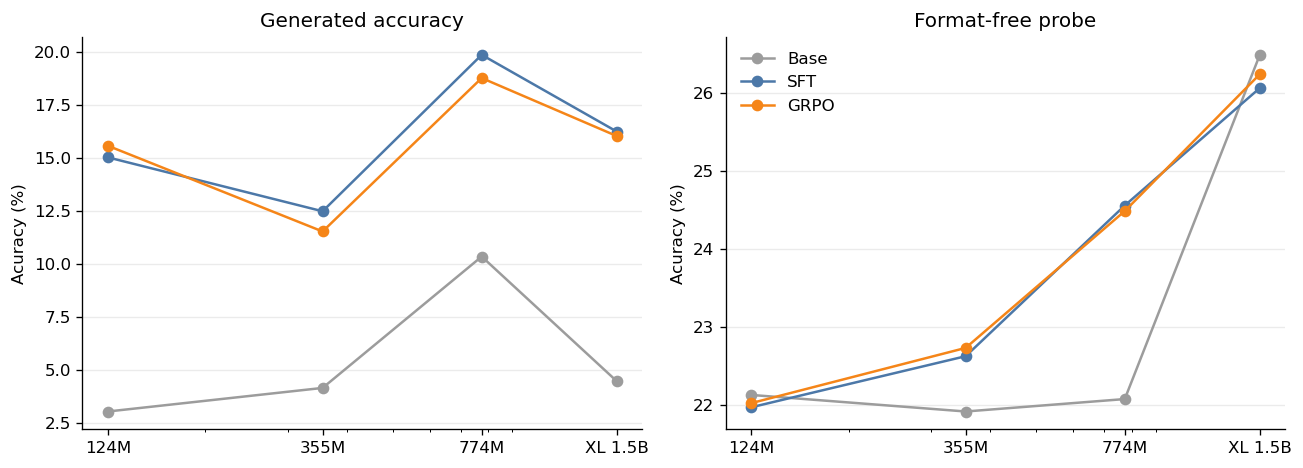

,scale,params,base_accuracy,SFT_accuracy,GRPO_accuracy,base_probe,SFT_probe,GRPO_probe,SFT_format,GRPO_format,SFT_coverage,GRPO_coverage,guard_failures,accuracy change,probe change,format change,coverage change
0,124M,0.1240,0.0303,0.1504,0.1559,0.2213,0.2197,0.2203,0.0234,0.0343,0.5784,0.6276,2,0.0055,0.0005,0.0110,0.0492
1,355M,0.3550,0.0414,0.1249,0.1154,0.2192,0.2263,0.2274,0.1368,0.2383,0.4701,0.4480,3,-0.0096,0.0011,0.1016,-0.0221
2,774M,0.7740,0.1035,0.1989,0.1879,0.2208,0.2456,0.2449,0.2730,0.3845,0.7376,0.6989,2,-0.0110,-0.0007,0.1115,-0.0387
3,XL 1.5B,1.5000,0.0446,0.1626,0.1605,0.2649,0.2606,0.2624,0.2806,0.4862,0.5870,0.5729,2,-0.0021,0.0018,0.2056,-0.0142


In [24]:
seed_rows = []
for scale, spec in GPT_SPECS.items():
    base = gpt_runs[scale]['base']
    for seed in SEEDS:
        run = gpt_runs[scale][seed]
        sft_coverage = 1 - run['sft']['eval']['extraction_failure_rate']
        grpo_coverage = 1 - run['grpo']['eval']['extraction_failure_rate']
        seed_rows.append({
            'scale': scale, 'params': spec['params'], 'seed': seed,
            'base accuracy': accuracy(base['rows']),
            'SFT accuracy': accuracy(run['sft']['rows']),
            'GRPO accuracy': accuracy(run['grpo']['rows']),
            'base probe': accuracy(base['probe_rows']),
            'SFT probe': accuracy(run['sft']['probe_rows']),
            'GRPO probe': accuracy(run['grpo']['probe_rows']),
            'SFT format': run['sft']['eval']['format_compliance'],
            'GRPO format': run['grpo']['eval']['format_compliance'],
            'SFT coverage': sft_coverage, 'GRPO coverage': grpo_coverage,
            'guard passes': min(sft_coverage, grpo_coverage) >= .5
                            and abs(grpo_coverage - sft_coverage) <= .02,
        })
seed_df = pd.DataFrame(seed_rows)
scale_df = seed_df.groupby(['scale', 'params'], sort=False).agg(
    base_accuracy=('base accuracy', 'first'), SFT_accuracy=('SFT accuracy', 'mean'),
    GRPO_accuracy=('GRPO accuracy', 'mean'), base_probe=('base probe', 'first'),
    SFT_probe=('SFT probe', 'mean'), GRPO_probe=('GRPO probe', 'mean'),
    SFT_format=('SFT format', 'mean'), GRPO_format=('GRPO format', 'mean'),
    SFT_coverage=('SFT coverage', 'mean'), GRPO_coverage=('GRPO coverage', 'mean'),
    guard_failures=('guard passes', lambda values: int((~values).sum())),
).reset_index()
scale_df['accuracy change'] = scale_df['GRPO_accuracy'] - scale_df['SFT_accuracy']
scale_df['probe change'] = scale_df['GRPO_probe'] - scale_df['SFT_probe']
scale_df['format change'] = scale_df['GRPO_format'] - scale_df['SFT_format']
scale_df['coverage change'] = scale_df['GRPO_coverage'] - scale_df['SFT_coverage']

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, suffix, title in ((axes[0], 'accuracy', 'Generated accuracy'),
                          (axes[1], 'probe', 'Format-free probe')):
    for stage in ('Base', 'SFT', 'GRPO'):
        column = f'{stage.lower()}_{suffix}' if stage == 'Base' else f'{stage}_{suffix}'
        ax.plot(scale_df['params'], scale_df[column] * 100, marker='o',
                color=COLORS[stage], label=stage)
    ax.set_xscale('log')
    ax.set_xticks(scale_df['params'], scale_df['scale'])
    ax.set_ylabel('Acuracy (%)')
    ax.set_title(title)
    ax.grid(axis='y', alpha=.25)
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / 'fig01_gpt2_endpoints.png', bbox_inches='tight')
plt.show()
display(scale_df.style.format(precision=4))

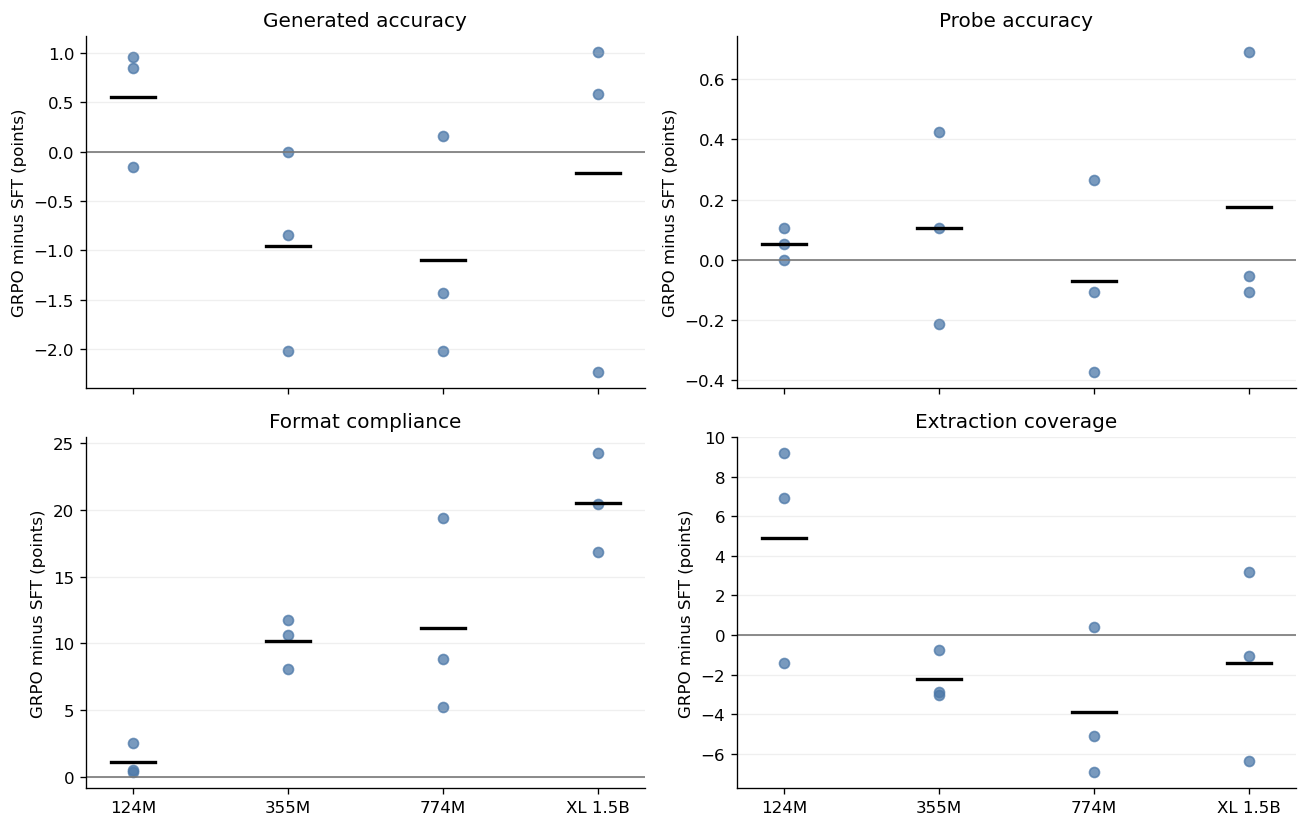

In [25]:
change_specs = (
    ('accuracy change', 'Generated accuracy'), ('probe change', 'Probe accuracy'),
    ('format change', 'Format compliance'), ('coverage change', 'Extraction coverage'),
)
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, (column, title) in zip(axes.flat, change_specs):
    for x, scale in enumerate(GPT_SPECS):
        left, right = column.split()
        values = (seed_df[seed_df.scale == scale][f'GRPO {left}']
                  - seed_df[seed_df.scale == scale][f'SFT {left}']) * 100
        ax.scatter([x] * len(values), values, color='#4C78A8', alpha=.75)
        ax.plot([x - .14, x + .14], [values.mean()] * 2, color='black', linewidth=2)
    ax.axhline(0, color='#777777', linewidth=1)
    ax.set_xticks(range(len(GPT_SPECS)), GPT_SPECS)
    ax.set_ylabel('GRPO minus SFT (points)')
    ax.set_title(title)
    ax.grid(axis='y', alpha=.2)
fig.tight_layout()
fig.savefig(FIG / 'fig02_gpt2_changes.png', bbox_inches='tight')
plt.show()

## Registered 774M comparisons

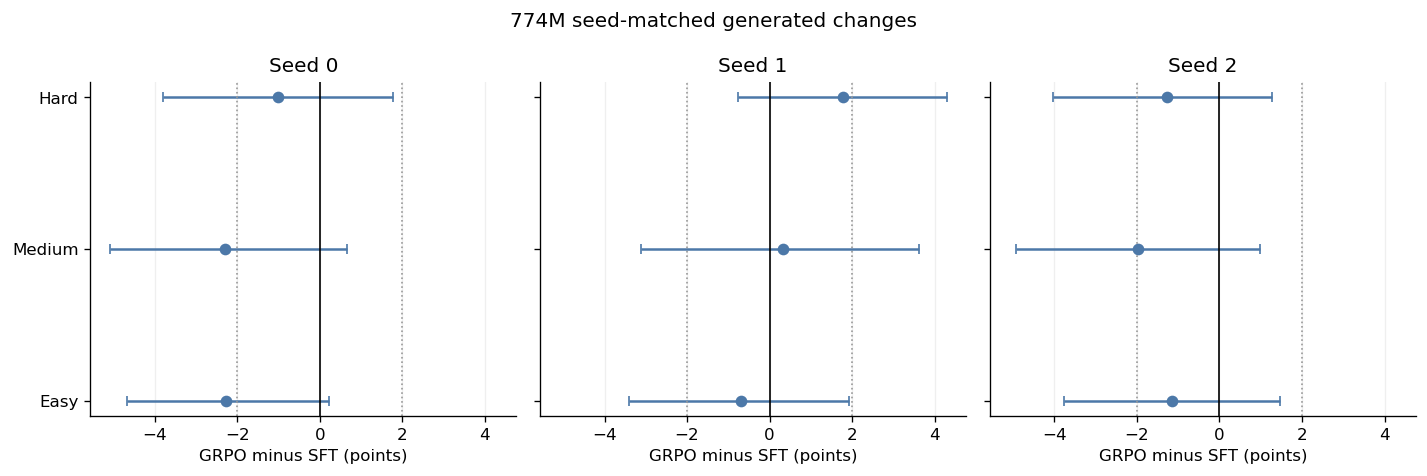

,seed,tier,delta,CI low,CI high,Holm p,category
0,0,easy,-0.022753,-0.046644,0.002275,0.787975,inconclusive
1,0,medium,-0.022989,-0.050903,0.006568,1.000000,inconclusive
2,0,hard,-0.010101,-0.037879,0.017677,1.000000,inconclusive
3,1,easy,-0.006826,-0.034130,0.019340,1.000000,inconclusive
4,1,medium,0.003284,-0.031199,0.036125,1.000000,inconclusive
5,1,hard,0.017677,-0.007576,0.042929,1.000000,inconclusive
6,2,easy,-0.011377,-0.037543,0.014790,1.000000,inconclusive
7,2,medium,-0.019704,-0.049261,0.009852,1.000000,inconclusive
8,2,hard,-0.012626,-0.040404,0.012626,1.000000,inconclusive


In [26]:
comparison_rows = []
for seed in SEEDS:
    sft_rows, grpo_rows = align_pred_rows(
        gpt_runs['774M'][seed]['sft']['rows'], gpt_runs['774M'][seed]['grpo']['rows'])
    for tier in TIERS:
        pairs = [(left, right) for left, right in zip(sft_rows, grpo_rows)
                 if left['tier'] == tier]
        before = [bool(left['correct']) for left, _ in pairs]
        after = [bool(right['correct']) for _, right in pairs]
        delta, low, high = paired_delta_ci(before, after, n_boot=10000, seed=seed)
        gains = sum(not left and right for left, right in zip(before, after))
        losses = sum(left and not right for left, right in zip(before, after))
        comparison_rows.append({
            'seed': seed, 'tier': tier, 'SFT': float(np.mean(before)),
            'GRPO': float(np.mean(after)), 'delta': delta,
            'CI low': low, 'CI high': high,
            'p': mcnemar_exact(gains, losses), 'gains': gains, 'losses': losses,
        })

adjusted = holm([row['p'] for row in comparison_rows])
for row, value in zip(comparison_rows, adjusted):
    row['Holm p'] = value
    if row['CI low'] > -.02 and row['CI high'] < .02:
        row['category'] = 'equivalent'
    elif row['delta'] >= .02 and value < .05:
        row['category'] = 'improvement'
    elif row['delta'] <= -.02 and value < .05:
        row['category'] = 'decline'
    else:
        row['category'] = 'inconclusive'
comparison_df = pd.DataFrame(comparison_rows)

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
for ax, seed in zip(axes, SEEDS):
    frame = comparison_df[comparison_df.seed == seed].set_index('tier').loc[list(TIERS)]
    y = np.arange(len(TIERS))
    x = frame.delta.to_numpy() * 100
    xerr = np.vstack((x - frame['CI low'].to_numpy() * 100,
                      frame['CI high'].to_numpy() * 100 - x))
    ax.errorbar(x, y, xerr=xerr, fmt='o', color='#4C78A8', capsize=3)
    ax.axvline(0, color='black', linewidth=1)
    ax.axvline(-2, color='#999999', linewidth=1, linestyle=':')
    ax.axvline(2, color='#999999', linewidth=1, linestyle=':')
    ax.set_title(f'Seed {seed}')
    ax.set_yticks(y, [tier.title() for tier in TIERS])
    ax.set_xlabel('GRPO minus SFT (points)')
    ax.grid(axis='x', alpha=.2)
fig.suptitle('774M seed-matched generated changes')
fig.tight_layout()
fig.savefig(FIG / 'fig03_m774_registered_changes.png', bbox_inches='tight')
plt.show()
display(comparison_df[['seed', 'tier', 'delta', 'CI low', 'CI high',
                       'Holm p', 'category']])

## Training dynamics

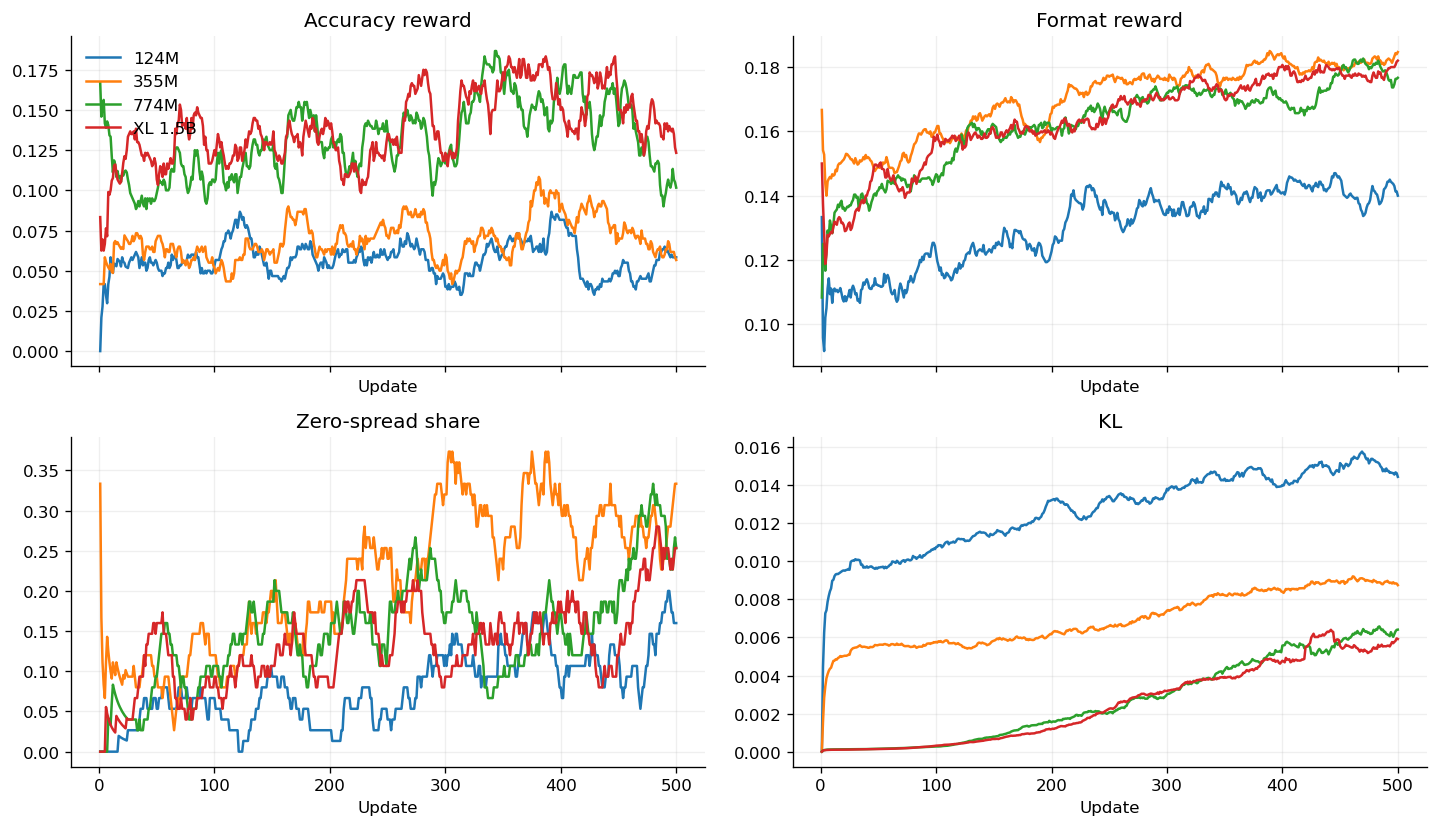

In [27]:
metric_specs = (
    ('rewards/accuracy_reward/mean', 'Accuracy reward'),
    ('rewards/format_reward/mean', 'Format reward'),
    ('frac_reward_zero_std', 'Zero-spread share'), ('kl', 'KL'),
)
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, (key, title) in zip(axes.flat, metric_specs):
    for scale in GPT_SPECS:
        frames = []
        for seed in SEEDS:
            frame = pd.DataFrame(gpt_runs[scale][seed]['trainlog'])
            frame = frame[frame.step.between(1, 500) & frame[key].notna()]
            frames.append(frame.set_index('step')[key].rename(seed))
        mean = pd.concat(frames, axis=1).mean(axis=1).rolling(25, min_periods=1).mean()
        ax.plot(mean.index, mean, label=scale)
    ax.set_title(title)
    ax.set_xlabel('Update')
    ax.grid(alpha=.2)
axes[0, 0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / 'fig04_training_dynamics.png', bbox_inches='tight')
plt.show()

## Separate Qwen2.5 context

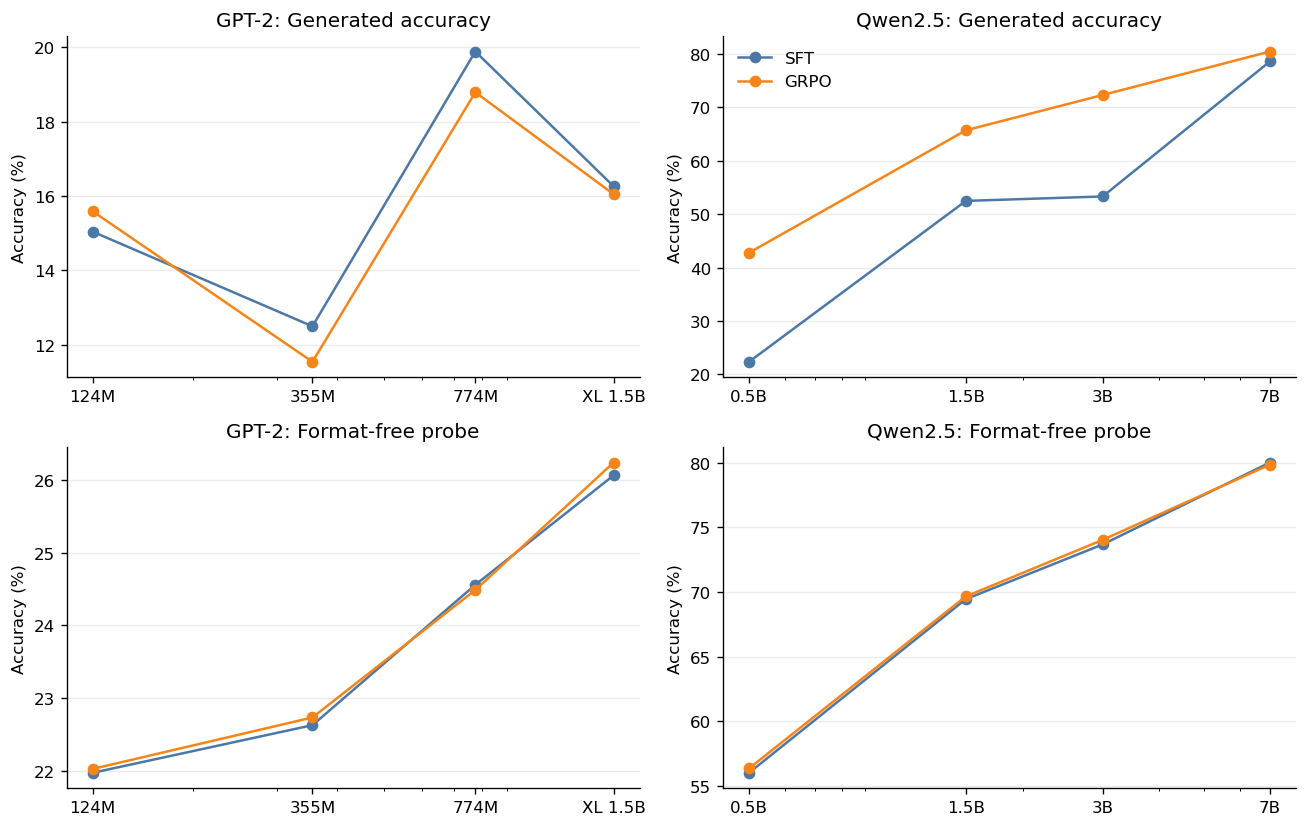

In [28]:
qwen_rows = []
for scale, spec in QWEN_SPECS.items():
    for seed in SEEDS:
        tag = spec['tag'].format(seed=seed)
        result_dir = RESULTS / tag
        manifest_path = result_dir / 'manifest.json'
        assert manifest_path.exists()
        source_hashes[tag] = sha256(str(manifest_path))
        qwen_rows.append({
            'scale': scale, 'params': spec['params'], 'seed': seed,
            'SFT accuracy': accuracy(read_rows(result_dir / 'sft_preds.jsonl')),
            'GRPO accuracy': accuracy(read_rows(result_dir / 'grpo_preds.jsonl')),
            'SFT probe': accuracy(read_rows(result_dir / 'sft_logprob_preds.jsonl')),
            'GRPO probe': accuracy(read_rows(result_dir / 'grpo_logprob_preds.jsonl')),
        })
qwen_seed_df = pd.DataFrame(qwen_rows)
qwen_df = qwen_seed_df.groupby(['scale', 'params'], sort=False).mean(numeric_only=True).reset_index()

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for column, title, row in (('accuracy', 'Generated accuracy', 0),
                           ('probe', 'Format-free probe', 1)):
    for col, (family, frame) in enumerate((('GPT-2', scale_df), ('Qwen2.5', qwen_df))):
        ax = axes[row, col]
        for stage in ('SFT', 'GRPO'):
            ax.plot(frame['params'], frame[f'{stage}_{column}' if family == 'GPT-2'
                                          else f'{stage} {column}'] * 100,
                    marker='o', color=COLORS[stage], label=stage)
        ax.set_xscale('log')
        ax.set_xticks(frame['params'], frame['scale'])
        ax.set_ylabel('Accuracy (%)')
        ax.set_title(f'{family}: {title}')
        ax.grid(axis='y', alpha=.25)
axes[0, 1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / 'fig05_separate_family_context.png', bbox_inches='tight')
plt.show()

## Direct GPT-2 and Qwen2.5 comparison

The two families are plotted together for context. This stays descriptive because architecture, tokenizer and pretraining all change between them; the GPT-2 generated endpoint is instrument limited.

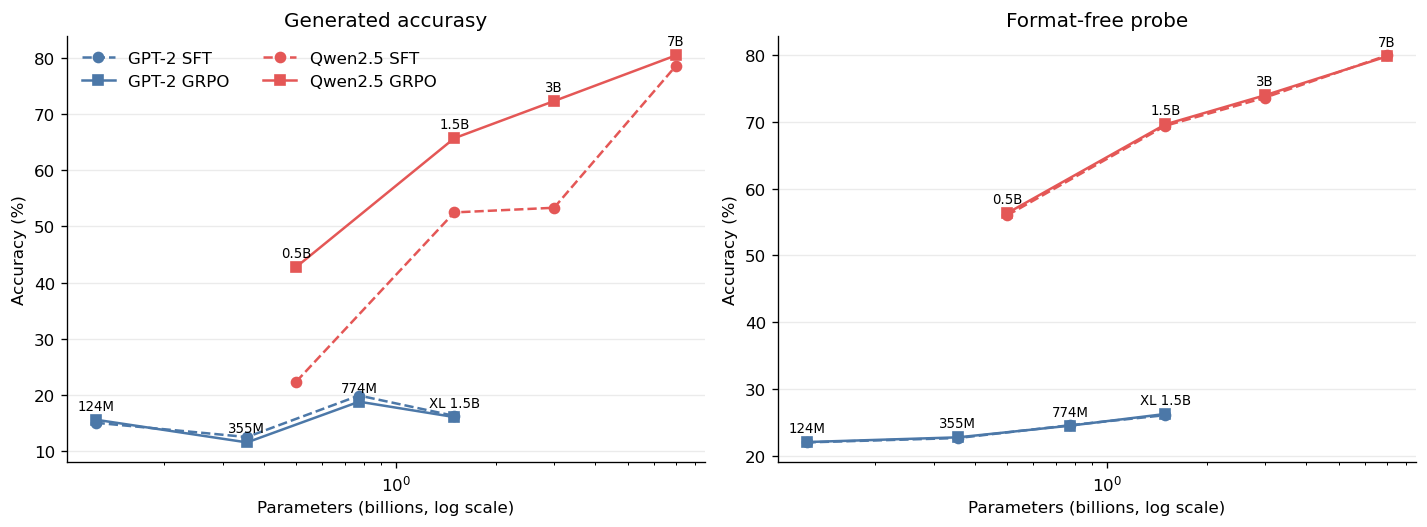

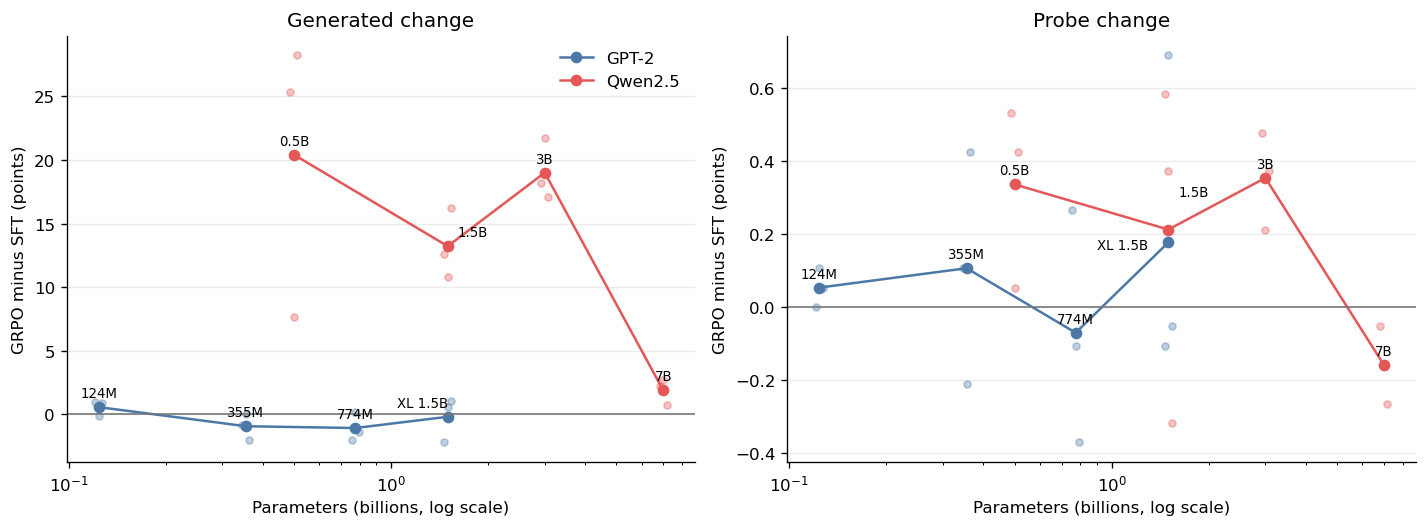

,family,model,params,SFT_accuracy,GRPO_accuracy,SFT_probe,GRPO_probe,generated change,probe change
0,GPT-2,124M,0.1240,0.1504,0.1559,0.2197,0.2203,0.0055,0.0005
1,GPT-2,355M,0.3550,0.1249,0.1154,0.2263,0.2274,-0.0096,0.0011
2,GPT-2,774M,0.7740,0.1989,0.1879,0.2456,0.2449,-0.0110,-0.0007
3,GPT-2,XL 1.5B,1.5000,0.1626,0.1605,0.2606,0.2624,-0.0021,0.0018
4,Qwen2.5,0.5B,0.5000,0.2236,0.4278,0.5602,0.5635,0.2042,0.0034
5,Qwen2.5,1.5B,1.5000,0.5249,0.6571,0.6944,0.6966,0.1322,0.0021
6,Qwen2.5,3B,3.0000,0.5333,0.7233,0.7367,0.7403,0.1900,0.0035
7,Qwen2.5,7B,7.0000,0.7861,0.8047,0.8001,0.7985,0.0186,-0.0016


In [29]:
gpt_seed_context = seed_df[
    ['scale', 'params', 'seed', 'SFT accuracy', 'GRPO accuracy',
     'SFT probe', 'GRPO probe']
].rename(columns={'scale': 'model'}).assign(family='GPT-2')
qwen_seed_context = qwen_seed_df[
    ['scale', 'params', 'seed', 'SFT accuracy', 'GRPO accuracy',
     'SFT probe', 'GRPO probe']
].rename(columns={'scale': 'model'}).assign(family='Qwen2.5')
family_seed_df = pd.concat([gpt_seed_context, qwen_seed_context], ignore_index=True)
family_df = family_seed_df.groupby(
    ['family', 'model', 'params'], sort=False
).agg(
    SFT_accuracy=('SFT accuracy', 'mean'),
    GRPO_accuracy=('GRPO accuracy', 'mean'),
    SFT_probe=('SFT probe', 'mean'),
    GRPO_probe=('GRPO probe', 'mean'),
).reset_index()
family_df['generated change'] = family_df['GRPO_accuracy'] - family_df['SFT_accuracy']
family_df['probe change'] = family_df['GRPO_probe'] - family_df['SFT_probe']

family_colours = {'GPT-2': '#4C78A8', 'Qwen2.5': '#E45756'}
stage_styles = {'SFT': ('--', 'o'), 'GRPO': ('-', 's')}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric, title in (
    (axes[0], 'accuracy', 'Generated accuracy'),
    (axes[1], 'probe', 'Format-free probe'),
):
    for family in ('GPT-2', 'Qwen2.5'):
        frame = family_df[family_df.family == family].sort_values('params')
        for stage, (line, marker) in stage_styles.items():
            ax.plot(frame.params, frame[f'{stage}_{metric}'] * 100,
                    linestyle=line, marker=marker, color=family_colours[family],
                    label=f'{family} {stage}')
        for row in frame.itertuples(index=False):
            ax.annotate(row.model, (row.params, getattr(row, f'GRPO_{metric}') * 100),
                        xytext=(0, 6), textcoords='offset points',
                        ha='center', fontsize=8)
    ax.set_xscale('log')
    ax.set_xlabel('Parameters (billions, log scale)')
    ax.set_ylabel('Accuracy (%)')
    ax.set_title(title)
    ax.grid(axis='y', alpha=.25)
axes[0].legend(frameon=False, ncol=2)
fig.tight_layout()
fig.savefig(FIG / 'fig06_qwen_gpt2_endpoints.png', bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, column, title in (
    (axes[0], 'generated change', 'Generated change'),
    (axes[1], 'probe change', 'Probe change'),
):
    seed_metric = 'accuracy' if column == 'generated change' else 'probe'
    for family in ('GPT-2', 'Qwen2.5'):
        means = family_df[family_df.family == family].sort_values('params')
        ax.plot(means.params, means[column] * 100, marker='o',
                color=family_colours[family], label=family)
        for _, row in means.iterrows():
            values = family_seed_df[
                (family_seed_df.family == family) &
                (family_seed_df.model == row['model'])
            ].sort_values('seed')
            seed_change = (values[f'GRPO {seed_metric}']
                           - values[f'SFT {seed_metric}']) * 100
            offsets = np.linspace(.975, 1.025, len(values))
            ax.scatter(row['params'] * offsets, seed_change,
                       color=family_colours[family], alpha=.35, s=18)
            offset, align = (0, 6), 'center'
            if row['params'] == 1.5:
                if column == 'probe change':
                    offset, align = ((-12, -4), 'right') if family == 'GPT-2' else ((6, 20), 'left')
                else:
                    offset = (-15 if family == 'GPT-2' else 15, 6)
            ax.annotate(row['model'], (row['params'], row[column] * 100),
                        xytext=offset, textcoords='offset points', ha=align, fontsize=8)
    ax.axhline(0, color='#777777', linewidth=1)
    ax.set_xscale('log')
    ax.set_xlabel('Parameters (billions, log scale)')
    ax.set_ylabel('GRPO minus SFT (points)')
    ax.set_title(title)
    ax.grid(axis='y', alpha=.25)
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / 'fig07_qwen_gpt2_changes.png', bbox_inches='tight')
plt.show()

family_df.to_csv(FIG / '048_1_qwen_gpt2_comparison.csv', index=False)
family_seed_df.to_csv(FIG / '048_1_qwen_gpt2_seed_values.csv', index=False)
display(family_df.style.format(precision=4))

## Exact values

In [30]:
training_rows = []
for scale in GPT_SPECS:
    for seed in SEEDS:
        frame = pd.DataFrame(gpt_runs[scale][seed]['trainlog'])
        frame = frame[frame.step.between(1, 500)]
        training_rows.append({
            'scale': scale, 'seed': seed,
            'accuracy reward': frame['rewards/accuracy_reward/mean'].mean(),
            'format reward': frame['rewards/format_reward/mean'].mean(),
            'zero-spread share': frame['frac_reward_zero_std'].mean(),
            'mean KL': frame['kl'].mean(),
        })
training_df = pd.DataFrame(training_rows)

scale_df.to_csv(FIG / '048_1_gpt2_scale_summary.csv', index=False)
seed_df.to_csv(FIG / '048_1_gpt2_seed_values.csv', index=False)
comparison_df.to_csv(FIG / '048_1_m774_registered_comparisons.csv', index=False)
training_df.to_csv(FIG / '048_1_training_summary.csv', index=False)
qwen_df.to_csv(FIG / '048_1_qwen_context.csv', index=False)

summary = {
    'completed': True, 'experiment': '048',
    'scope': 'four-scale GPT-2 LoRA family', 'seeds': list(SEEDS),
    'gpt2_scales': json.loads(scale_df.to_json(orient='records')),
    'm774_registered_comparisons': json.loads(comparison_df.to_json(orient='records')),
    'training_summary': json.loads(training_df.to_json(orient='records')),
    'qwen_context': json.loads(qwen_df.to_json(orient='records')),
    'source_record_sha256': source_hashes,
}
atomic_write_json(str(RESULTS / '048_family_summary.json'), summary)
display(scale_df.style.format(precision=4))
display(training_df.groupby('scale', sort=False).mean(numeric_only=True).style.format(precision=4))
print('wrote', RESULTS / '048_family_summary.json')

,scale,params,base_accuracy,SFT_accuracy,GRPO_accuracy,base_probe,SFT_probe,GRPO_probe,SFT_format,GRPO_format,SFT_coverage,GRPO_coverage,guard_failures,accuracy change,probe change,format change,coverage change
0,124M,0.1240,0.0303,0.1504,0.1559,0.2213,0.2197,0.2203,0.0234,0.0343,0.5784,0.6276,2,0.0055,0.0005,0.0110,0.0492
1,355M,0.3550,0.0414,0.1249,0.1154,0.2192,0.2263,0.2274,0.1368,0.2383,0.4701,0.4480,3,-0.0096,0.0011,0.1016,-0.0221
2,774M,0.7740,0.1035,0.1989,0.1879,0.2208,0.2456,0.2449,0.2730,0.3845,0.7376,0.6989,2,-0.0110,-0.0007,0.1115,-0.0387
3,XL 1.5B,1.5000,0.0446,0.1626,0.1605,0.2649,0.2606,0.2624,0.2806,0.4862,0.5870,0.5729,2,-0.0021,0.0018,0.2056,-0.0142


,seed,accuracy reward,format reward,zero-spread share,mean KL
scale,,,,,
124M,1.0000,0.0572,0.1310,0.0827,0.0129
355M,1.0000,0.0695,0.1707,0.2200,0.0071
774M,1.0000,0.1313,0.1632,0.1540,0.0028
XL 1.5B,1.0000,0.1395,0.1649,0.1373,0.0027


wrote /Users/oleggastov/Desktop/University UK/0006_City n St Georges Universities/003_Projects/INM363-IndividualProject-Dissertation/001_Code/results/048_family_summary.json


## Cross-referenced conclusion

12 GPT-2 arms completed. From 124M to XL 1.5B. Mean format-free probe change stays between -0.07 and +0.18 points, while format compliance improves more clearly as the checkpoints grow. Generated accuracy is instrument limited at every scale because at least two seeds fail the extraction guard.

Each 774M tier comparison is unconvincing after correction. The separate Qwen2.5 panels show stronger generated gains, but they don't isolate a single cause because architecture, tokenizer and pretraining change with the model family. The family result is that GPT-2 LoRA GRPO changes response formatting without adding detectable MMLU answer knowledge under this pipeline.